# Stage 1 - Fine-tune BARTpho trên VietNews

Mục tiêu: huấn luyện model học **task summarization tiếng Việt** làm bệ phóng cho Stage 2 (domain y tế VnExpress).

Cấu hình chính:
- Backbone: `vinai/bartpho-word`
- Dữ liệu: `nam194/vietnews`, lấy ~30k mẫu train có length ratio gần với domain đích (0.15-0.30)
- 3 epoch, bf16, batch 16, beam=1 khi eval (greedy) cho nhanh
- Đánh giá Stage 1 trên 2,000 mẫu test (cùng filter, cùng seed với file ViT5 để so sánh fair)

Chọn 30k vì:
- BARTpho-word checkpoint gốc chưa từng thấy summarization → cần đủ data để internalize task
- Stage 2 nhỏ (780 raw / 2.3k augmented) → không thể vừa học task vừa học domain
- 30k là sweet spot literature cho intermediate fine-tuning, ratio S1:S2 ~13× với augmented data
- Dưới 20k thường task chưa "chín"; trên 50k bắt đầu soak source style

In [1]:
!pip install -q -U transformers==4.46.3 datasets==3.1.0 evaluate==0.4.3 rouge_score==0.1.2 accelerate==1.1.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 500.3 kB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.2/333.2 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 49.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.9.0 which is incompatible.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import json
import time
import random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import evaluate

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
from tqdm.auto import tqdm

In [4]:
# Tập trung mọi đường dẫn ở một nơi để dễ sửa
BASE_DIR    = "/content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/BARTpho_stage_1"
DATA_DIR    = f"{BASE_DIR}/data/vietnews"
MODEL_DIR   = f"{BASE_DIR}/models/stage1_bartpho"
FINAL_DIR   = f"{MODEL_DIR}/final_model"
METRICS_DIR = f"{BASE_DIR}/metrics/plots"
EVAL_DIR    = f"{BASE_DIR}/metrics/test_eval"

for d in (DATA_DIR, MODEL_DIR, METRICS_DIR, EVAL_DIR):
    os.makedirs(d, exist_ok=True)

MODEL_CHECKPOINT = "vinai/bartpho-word"
MAX_INPUT_LEN    = 1024
MAX_TARGET_LEN   = 256
SEED             = 42

TRAIN_SIZE = 20000
VAL_SIZE   = 2000
TEST_SIZE  = 2000

# Generate config dùng chung cho test - giữ y hệt giữa BARTpho và ViT5 để fair
GEN_MAX_LEN   = 160
GEN_NUM_BEAMS = 4
GEN_BATCH     = 8

# 1. Tải và xử lý dữ liệu

Stage 2 dùng domain y tế VnExpress với length ratio 0.20-0.25 và độ dài bài 250-2500 từ. Để giảm shock giữa hai stage, ta lọc VietNews giữ các mẫu có đặc tính gần tương tự (nới lỏng nhẹ ratio xuống 0.15-0.30) trước khi lấy mẫu. Filter này áp cho cả train/val/test.

In [ ]:
print("Đang tải bộ dữ liệu VietNews...")
dataset = load_dataset("nam194/vietnews")
print(dataset)

Đang tải bộ dữ liệu VietNews...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['guid', 'title', 'abstract', 'article'],
        num_rows: 99134
    })
    validation: Dataset({
        features: ['guid', 'title', 'abstract', 'article'],
        num_rows: 22184
    })
    test: Dataset({
        features: ['guid', 'title', 'abstract', 'article'],
        num_rows: 22498
    })
})


In [ ]:
# Filter theo độ dài và length ratio để gần với domain đích (Stage 2)
def keep_close_to_target(example):
    src_words = len(example["article"].split())
    tgt_words = len(example["abstract"].split())
    if src_words < 100 or src_words > 1500:
        return False
    if tgt_words < 15 or tgt_words > 150:
        return False
    ratio = tgt_words / src_words
    return 0.05 <= ratio <= 0.45

filtered_train = dataset["train"].filter(keep_close_to_target)
filtered_val   = dataset["validation"].filter(keep_close_to_target)
filtered_test  = dataset["test"].filter(keep_close_to_target)
print(f"Train sau filter: {len(filtered_train):,} | Val: {len(filtered_val):,} | Test: {len(filtered_test):,}")

train_dataset = filtered_train.shuffle(seed=SEED).select(range(min(TRAIN_SIZE, len(filtered_train))))
val_dataset   = filtered_val.shuffle(seed=SEED).select(range(min(VAL_SIZE, len(filtered_val))))
test_dataset  = filtered_test.shuffle(seed=SEED).select(range(min(TEST_SIZE, len(filtered_test))))
print(f"Train dùng: {len(train_dataset):,} | Val dùng: {len(val_dataset):,} | Test dùng: {len(test_dataset):,}")

Train sau filter: 77,564 | Val: 17,316 | Test: 17,622
Train dùng: 20,000 | Val dùng: 2,000 | Test dùng: 2,000


In [ ]:
# Xuất dữ liệu thô ra JSONL để dễ kiểm tra / tái lập
train_dataset.to_json(f"{DATA_DIR}/train_{len(train_dataset)}.jsonl", force_ascii=False)
val_dataset.to_json(f"{DATA_DIR}/val_{len(val_dataset)}.jsonl", force_ascii=False)
test_dataset.to_json(f"{DATA_DIR}/test_{len(test_dataset)}.jsonl", force_ascii=False)
print(f"Đã lưu dữ liệu thô tại: {DATA_DIR}")

Creating json from Arrow format:   0%|          | 0/20 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Đã lưu dữ liệu thô tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/BARTpho_stage_1/data/vietnews


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def preprocess_function(examples):
    model_inputs = tokenizer(
        examples["article"],
        max_length=MAX_INPUT_LEN,
        truncation=True,
    )
    labels = tokenizer(
        text_target=examples["abstract"],
        max_length=MAX_TARGET_LEN,
        truncation=True,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

In [ ]:
print("Đang tokenize dữ liệu...")
tokenized_train = train_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=train_dataset.column_names,
)
tokenized_val = val_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=val_dataset.column_names,
)
print("Đã chuẩn bị xong dữ liệu huấn luyện.")

Đang tokenize dữ liệu...
Đã chuẩn bị xong dữ liệu huấn luyện.


# 2. Hàm đánh giá (ROUGE)

Tiếng Việt không dùng được Porter stemmer (vốn cho tiếng Anh) nên đặt `use_stemmer=False`. Ta cũng xử lý cả `-100` ở predictions phòng trường hợp generate bị pad.

In [5]:
rouge = evaluate.load("rouge")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
    labels      = np.where(labels      != -100, labels,      tokenizer.pad_token_id)

    decoded_preds  = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels,      skip_special_tokens=True)

    decoded_preds  = ["\n".join(p.strip().split()) for p in decoded_preds]
    decoded_labels = ["\n".join(l.strip().split()) for l in decoded_labels]

    result = rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=False,
    )
    return {k: round(v * 100, 4) for k, v in result.items()}

print("Đã cài đặt hàm đánh giá ROUGE.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Đã cài đặt hàm đánh giá ROUGE.


# 3. Training

Cấu hình:
- `bf16=True` cho A100 (đổi sang `fp16=True` nếu chạy trên T4/L4)
- `batch=16` x `grad_accum=2` => effective batch = 32
- `num_train_epochs=3` đủ cho intermediate fine-tuning, tránh overfit vào VietNews
- Eval với `num_beams=1` (greedy) cho nhanh; sẽ chạy beam search ở cell test cuối

In [ ]:
print("Đang nạp mô hình BARTpho...")
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CHECKPOINT)
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

training_args = Seq2SeqTrainingArguments(
    output_dir=MODEL_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    warmup_ratio=0.05,
    num_train_epochs=5,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    predict_with_generate=True,
    generation_max_length=160,
    generation_num_beams=1,
    bf16=True,
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

Đang nạp mô hình BARTpho...


In [ ]:
print("Bắt đầu huấn luyện Stage 1...")
trainer.train()

trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Huấn luyện hoàn tất. Model tốt nhất đã lưu tại: {FINAL_DIR}")

Bắt đầu huấn luyện Stage 1...


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,2.120700,1.980075,60.443700,29.936800,39.589900,60.304100
2,1.747700,1.970328,60.216200,29.616500,39.567100,60.033900
3,1.390300,2.032142,60.879700,30.257300,40.182300,60.730500
4,1.128400,2.086481,60.905000,29.969500,39.877800,60.719000


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Huấn luyện hoàn tất. Model tốt nhất đã lưu tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/BARTpho_stage_1/models/stage1_bartpho/final_model


# Phụ

In [6]:
import os
import json
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

print("🔍 Đang rà soát ổ đĩa để tìm các checkpoint...")

# 1. Tìm tất cả các thư mục có chữ "checkpoint-" nằm trong MODEL_DIR
checkpoints = [os.path.join(MODEL_DIR, d) for d in os.listdir(MODEL_DIR) if d.startswith("checkpoint-")]

if not checkpoints:
    print("❌ Lỗi: Không tìm thấy bất kỳ thư mục checkpoint nào trên Google Drive.")
    print("Có thể quá trình huấn luyện chưa kịp lưu, hoặc đường dẫn MODEL_DIR bị sai.")
else:
    # 2. Sắp xếp để lấy thư mục checkpoint mới nhất (vì nó sẽ chứa file lịch sử đầy đủ nhất)
    checkpoints.sort(key=lambda x: int(x.split("-")[-1]))
    latest_checkpoint = checkpoints[-1]

    state_file = os.path.join(latest_checkpoint, "trainer_state.json")

    if os.path.exists(state_file):
        # 3. Đọc file lịch sử để tìm "best_model_checkpoint"
        with open(state_file, "r", encoding="utf-8") as f:
            state = json.load(f)

        best_ckpt = state.get("best_model_checkpoint", None)

        if best_ckpt and os.path.exists(best_ckpt):
            print(f"🌟 Tuyệt vời! Đã tìm thấy Checkpoint xịn nhất tại: {best_ckpt}")
        else:
            print("⚠️ Không tìm thấy nhãn 'best_model', sẽ sử dụng ngay checkpoint mới nhất để thay thế...")
            best_ckpt = latest_checkpoint

        # 4. Nạp model và lưu đè vào thư mục đích
        print("⏳ Đang nạp trọng số từ Checkpoint...")
        best_model = AutoModelForSeq2SeqLM.from_pretrained(best_ckpt)
        best_tokenizer = AutoTokenizer.from_pretrained(best_ckpt)

        # Tắt cảnh báo
        best_model.config.tie_word_embeddings = False

        print(f"💾 Đang bung file và lưu cứng vào thư mục: {FINAL_DIR} ...")
        os.makedirs(FINAL_DIR, exist_ok=True)
        best_model.save_pretrained(FINAL_DIR)
        best_tokenizer.save_pretrained(FINAL_DIR)

        print("✅ CHIẾN DỊCH GIẢI CỨU HOÀN TẤT! Em có thể chuyển sang Cell 5 để Test được rồi.")
    else:
        print(f"❌ Lỗi: Không tìm thấy file 'trainer_state.json' trong thư mục {latest_checkpoint}.")

🔍 Đang rà soát ổ đĩa để tìm các checkpoint...
⚠️ Không tìm thấy nhãn 'best_model', sẽ sử dụng ngay checkpoint mới nhất để thay thế...
⏳ Đang nạp trọng số từ Checkpoint...
💾 Đang bung file và lưu cứng vào thư mục: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/BARTpho_stage_1/models/stage1_bartpho/final_model ...
✅ CHIẾN DỊCH GIẢI CỨU HOÀN TẤT! Em có thể chuyển sang Cell 5 để Test được rồi.


# 4. Biểu đồ loss

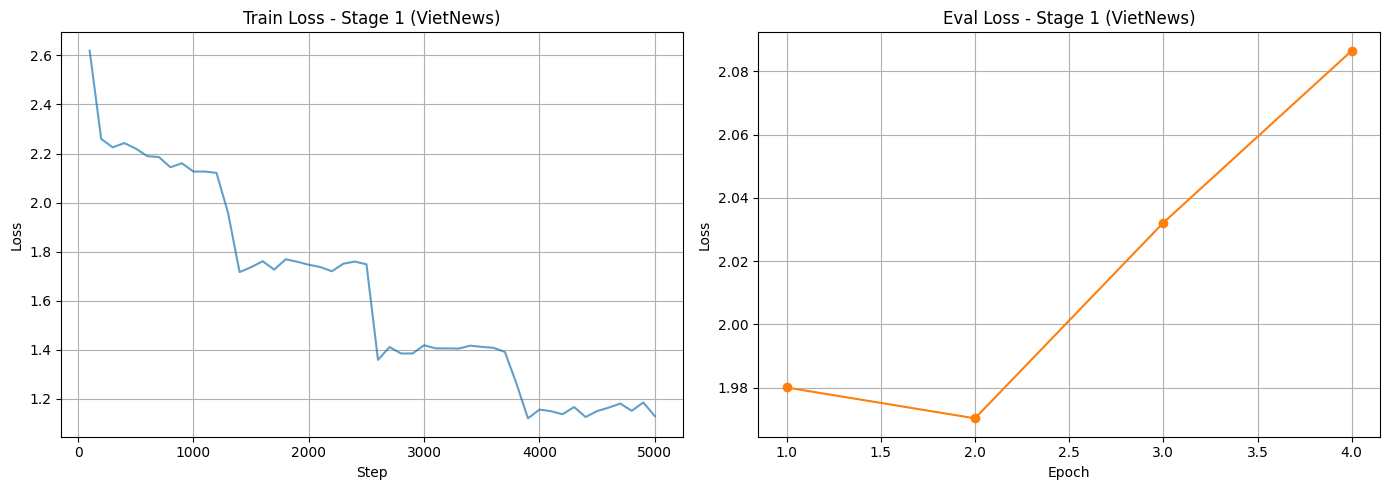

Đã lưu biểu đồ tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/BARTpho_stage_1/metrics/plots/stage1_loss.png


In [ ]:
log_history = trainer.state.log_history

train_steps, train_loss = [], []
eval_epochs, eval_loss  = [], []

for entry in log_history:
    if "loss" in entry and "step" in entry and "eval_loss" not in entry:
        train_steps.append(entry["step"])
        train_loss.append(entry["loss"])
    elif "eval_loss" in entry and "epoch" in entry:
        eval_epochs.append(entry["epoch"])
        eval_loss.append(entry["eval_loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_steps, train_loss, color="tab:blue", alpha=0.7)
axes[0].set_title("Train Loss - Stage 1 (VietNews)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(eval_epochs, eval_loss, marker="o", color="tab:orange")
axes[1].set_title("Eval Loss - Stage 1 (VietNews)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True)

plt.tight_layout()
plot_path = f"{METRICS_DIR}/stage1_loss.png"
plt.savefig(plot_path, dpi=120)
plt.show()
print(f"Đã lưu biểu đồ tại: {plot_path}")

# 5. Đánh giá trên tập test

Generate trên `test_dataset` (2,000 mẫu, cùng filter & seed với file ViT5) bằng beam search 4. Tính ROUGE-1/2/L và lưu predictions ra JSONL để đối chiếu định tính với model còn lại.

In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Load lại best checkpoint để đảm bảo state sạch (tránh phụ thuộc vào trainer.model)
eval_tokenizer = AutoTokenizer.from_pretrained(FINAL_DIR)
eval_model     = AutoModelForSeq2SeqLM.from_pretrained(FINAL_DIR).to(DEVICE)
eval_model.eval()

preds, refs = [], []
start = time.time()

with torch.no_grad():
    for i in tqdm(range(0, len(test_dataset), GEN_BATCH), desc="Generate test"):
        batch = test_dataset[i:i + GEN_BATCH]
        inputs = eval_tokenizer(
            batch["article"],
            max_length=MAX_INPUT_LEN,
            truncation=True,
            padding=True,
            return_tensors="pt",
        ).to(DEVICE)

        out = eval_model.generate(
            **inputs,
            max_length=GEN_MAX_LEN,
            num_beams=GEN_NUM_BEAMS,
            no_repeat_ngram_size=3,
            early_stopping=True,
        )
        decoded = eval_tokenizer.batch_decode(out, skip_special_tokens=True)
        preds.extend(decoded)
        refs.extend(batch["abstract"])

elapsed = time.time() - start
print(f"Generate xong {len(preds)} mẫu trong {elapsed:.1f}s ({elapsed/len(preds)*1000:.1f} ms/mẫu)")

Generate test:   0%|          | 0/250 [00:00<?, ?it/s]

ValueError: The following `model_kwargs` are not used by the model: ['token_type_ids'] (note: typos in the generate arguments will also show up in this list)

In [ ]:
def normalize(text):
    return "\n".join(text.strip().split())

test_result = rouge.compute(
    predictions=[normalize(p) for p in preds],
    references=[normalize(r) for r in refs],
    use_stemmer=False,
)
test_result = {k: round(v * 100, 4) for k, v in test_result.items()}
test_result["latency_ms_per_sample"] = round(elapsed / len(preds) * 1000, 2)
test_result["n_samples"] = len(preds)
test_result["model"] = "BARTpho-word (Stage 1)"

df = pd.DataFrame([test_result])
print(df.to_string(index=False))

# Lưu kết quả
with open(f"{EVAL_DIR}/stage1_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_result, f, ensure_ascii=False, indent=2)
df.to_csv(f"{EVAL_DIR}/stage1_test_metrics.csv", index=False)
print(f"\nĐã lưu metrics tại: {EVAL_DIR}")

In [ ]:
preds_path = f"{EVAL_DIR}/stage1_test_predictions.jsonl"
with open(preds_path, "w", encoding="utf-8") as f:
    for i in range(len(test_dataset)):
        row = {
            "guid": test_dataset[i].get("guid"),
            "article": test_dataset[i]["article"],
            "reference": test_dataset[i]["abstract"],
            "prediction": preds[i],
        }
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print(f"Đã lưu {len(preds)} predictions tại: {preds_path}")

In [ ]:
# Xem nhanh 3 ví dụ ngẫu nhiên để cảm nhận chất lượng
random.seed(SEED)
for idx in random.sample(range(len(test_dataset)), 3):
    print("=" * 80)
    print(f"[Sample {idx}]")
    print("-- Reference --")
    print(test_dataset[idx]["abstract"])
    print("-- BARTpho prediction --")
    print(preds[idx])
    print()